# EVC Landing Estimator

Estimate which last-click channels (Direct, Brand Search, Affiliate, etc.) are absorbing your Google Ads YouTube **Engaged-View Conversions (EVCs)** from daily CRM, UTM, or GA4 exports.

> **Not incrementality or ROI:** EVCs are double-counted conversions. This notebook estimates *where* they land under last-click, with block-bootstrap uncertainty, a planted-signal power test, and a future-EVC confounding check.


In [1]:
# Install in Google Colab (uncomment if running in a fresh Colab runtime):
# %pip install -q git+https://github.com/Benfinkels/evc-landing-estimator.git
import evc_landing_estimator
print("evc-landing-estimator", evc_landing_estimator.TOOL_VERSION)


evc-landing-estimator 2.0.0


In [2]:
# Optional: upload your own CSV/XLSX exports in Google Colab
try:
    from google.colab import files
    uploaded = files.upload()
except ImportError:
    print("Running outside Colab; using local or bundled example files.")


Running outside Colab; using local or bundled example files.


In [3]:
from pathlib import Path
from evc_landing_estimator import Config, run
from evc_landing_estimator.pipeline import preview_map

CONVERSIONS_PATH = Path("../examples/crm_leads_rowlevel.csv")
EVC_PATH = Path("../examples/google_ads_evc_daily.csv")
OUT_DIR = Path("../out/notebook_demo")

config = Config(
    ads_tz="America/New_York",
    source_tz="UTC",
    date_basis="impression_time",  # or "conversion_time"
    max_lag=3,
    brand_terms=["acme"],
    bootstrap=500,
    power_bootstrap=100,
    seed=42,
)


In [4]:
# Preview deterministic channel mapping and check for unmapped raw values
mapped = preview_map(CONVERSIONS_PATH, config)
print("Mapped channels:", list(mapped.conv_daily.columns))
print("Unmapped rows:", len(mapped.unmapped))


Mapped channels: ['Affiliate', 'Direct', 'Email/SMS', 'Organic Brand Search', 'Organic Non-Brand Search', 'Paid Brand Search', 'Paid Non-Brand Search', 'Paid Social']
Unmapped rows: 0


In [5]:
# Run full constrained share estimator, power test, and lead falsification check
result = run(CONVERSIONS_PATH, EVC_PATH, config=config, out_dir=OUT_DIR)
print(result.summary_text)


Most likely landing channel: Direct (39%, 90% CI 33%–47%, P(#1) = 99%). Also likely: Paid Brand Search (20%), Affiliate (15%), Organic Brand Search (9%). Inconclusive: Email/SMS, Paid Social, Organic Non-Brand Search, Paid Non-Brand Search. About 13% of EVCs are not visible in this data.


Most likely landing channel: Direct (39%, 90% CI 33%–47%, P(#1) = 99%). Also likely: Paid Brand Search (20%), Affiliate (15%), Organic Brand Search (9%). Inconclusive: Email/SMS, Paid Social, Organic Non-Brand Search, Paid Non-Brand Search. About 13% of EVCs are not visible in this data.

Bucket                     | Share | 90% CI        | P(#1) | Confidence
------------------------------------------------------------------------
Direct                     | 39.3% | 33.0% - 47.0% |  99%  | Strong
Paid Brand Search          | 20.0% | 9.7% - 27.2% |   1%  | Directional
Affiliate                  | 15.1% | 9.5% - 20.0% |   0%  | Directional
Organic Brand Search       |  9.1% | 4.1% - 15.4% |   0%  | Directional
Email/SMS                  |  2.5% | 0.0% -  8.3% |   0%  | Inconclusive
Paid Social                |  1.5% | 0.0% -  6.3% |   0%  | Inconclusive
Organic Non-Brand Search   |  0.0% | 0.0% -  5.3% |   0%  | Inconclusive
Paid Non-Brand Search      |  0.0% | 0.0% -  5.2% |   0%  | In

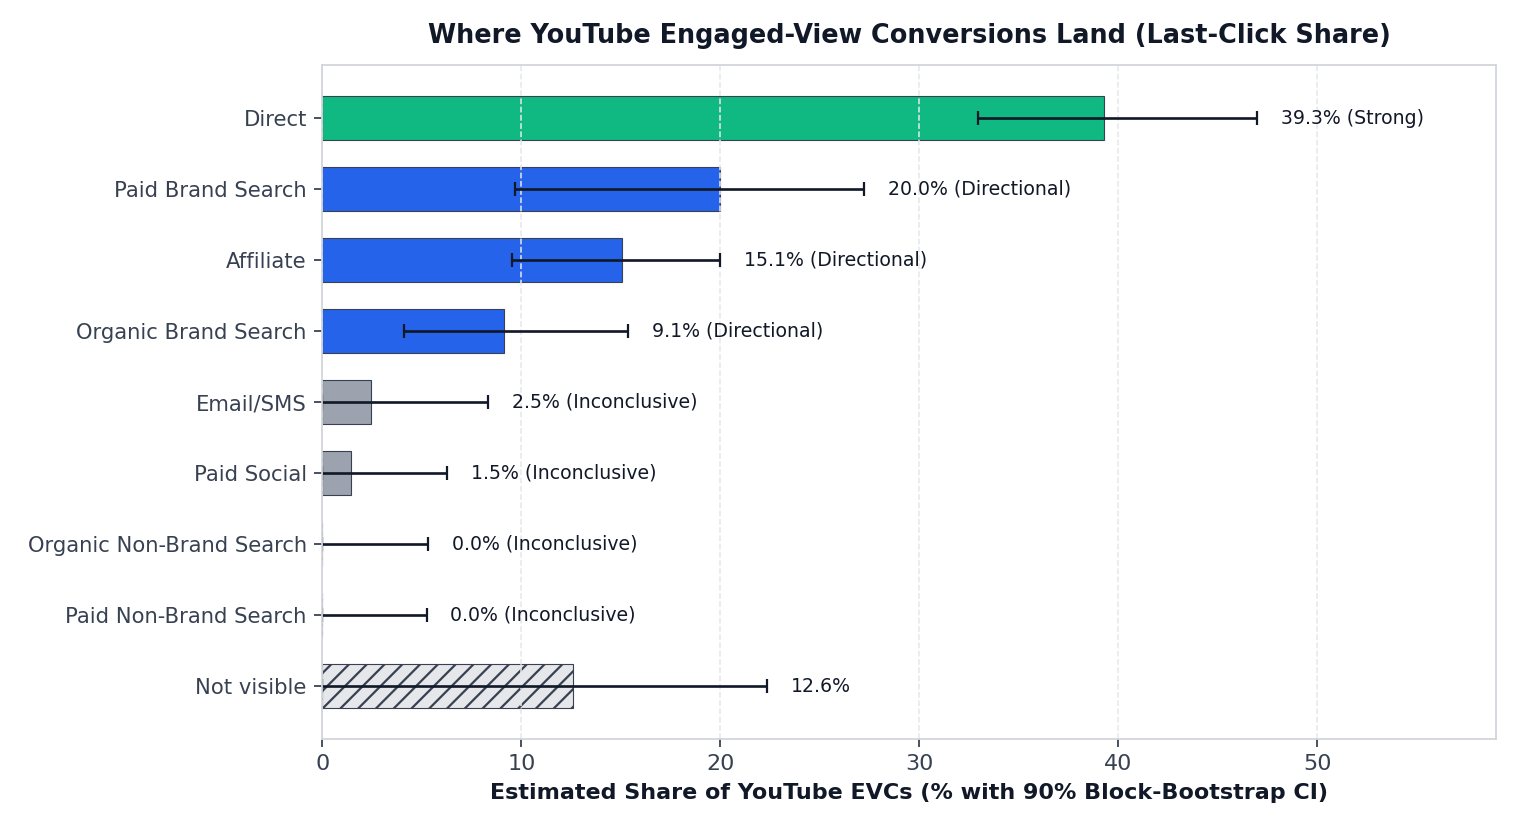

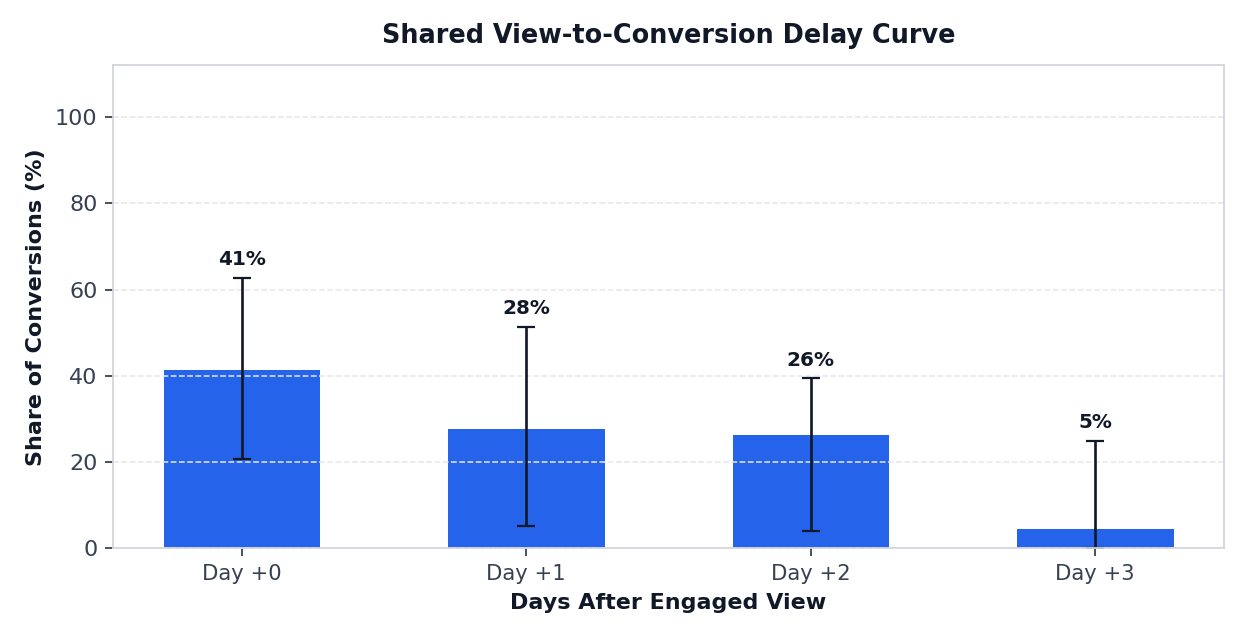

In [6]:
# Display channel table and diagnostic charts
from IPython.display import Image, display
import pandas as pd

df_res = pd.DataFrame([
    {"Bucket": c.bucket, "Share": f"{c.share:.1%}", "90% CI": f"{c.ci_low:.1%} - {c.ci_high:.1%}",
     "P(#1)": f"{c.p_top:.0%}", "Label": c.label, "Powered": c.powered}
    for c in result.channels
])
print(df_res.to_string(index=False))
display(Image(filename=result.output_files["chart_shares"]))
display(Image(filename=result.output_files["chart_delay_curve"]))


In [7]:
# Inspect generated self-contained HTML report and 8-sheet XLSX workbook
for name, path in result.output_files.items():
    print(f"{name}: {path}")


json: ../out/notebook_demo/results.json
xlsx: ../out/notebook_demo/results.xlsx
html: ../out/notebook_demo/report.html
